In [1]:
# Yoseva Faurensia Sitohang_202431195

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
# Yoseva Faurensia Sitohang_202431195

df = pd.read_csv("winequality-red.csv")

In [3]:
# Yoseva Faurensia Sitohang_202431195

print("5 Data Pertama:")
display(df.head())

5 Data Pertama:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
# Yoseva Faurensia Sitohang_202431195

print("Informasi Dataset:")
df.info()

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [5]:
# Yoseva Faurensia Sitohang_202431195

print("Statistik Deskriptif:")
display(df.describe())

Statistik Deskriptif:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [6]:
# Yoseva Faurensia Sitohang_202431195

df_clean = df.copy()

print("Nilai Kosong Sebelum Pembersihan:")
print(df_clean.isna().sum())

df_clean = df_clean.drop(columns=['ID'], errors='ignore')

df_clean = df_clean.fillna(df_clean.median(numeric_only=True))

print("\nNilai Kosong Setelah Pembersihan:")
print(df_clean.isna().sum())

Nilai Kosong Sebelum Pembersihan:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Nilai Kosong Setelah Pembersihan:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [7]:
# Yoseva Faurensia Sitohang_202431195

fitur = df_clean[['alcohol', 'volatile acidity']]
print("Data Fitur Clustering:")
display(fitur.head())

print("\nKorelasi Antarfitur:")
display(fitur.corr().round(4))

Data Fitur Clustering:


,alcohol,volatile acidity
0,9.4,0.70
1,9.8,0.88
2,9.8,0.76
3,9.8,0.28
4,9.4,0.70



Korelasi Antarfitur:


,alcohol,volatile acidity
alcohol,1.0000,-0.2023
volatile acidity,-0.2023,1.0000


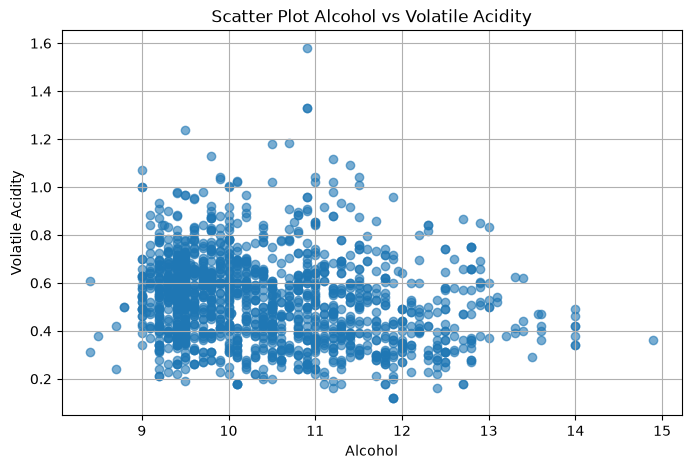

In [8]:
# Yoseva Faurensia Sitohang_202431195

plt.figure(figsize=(8, 5))
plt.scatter(
    fitur['alcohol'],
    fitur['volatile acidity'],
    alpha=0.6
)

plt.title('Scatter Plot Alcohol vs Volatile Acidity')
plt.xlabel('Alcohol')
plt.ylabel('Volatile Acidity')
plt.grid(True)
plt.show()

In [9]:
# Yoseva Faurensia Sitohang_202431195

scaler = StandardScaler()
fitur_scaled = scaler.fit_transform(fitur)

df_scaled = pd.DataFrame(
    fitur_scaled,
    columns=fitur.columns)

print("Rata-rata Setelah Standardisasi:")
print(df_scaled.mean())

print("\nStandar Deviasi Setelah Standardisasi:")
print(df_scaled.std())

Rata-rata Setelah Standardisasi:
alcohol             1.066481e-16
volatile acidity    1.733031e-16
dtype: float64

Standar Deviasi Setelah Standardisasi:
alcohol             1.000313
volatile acidity    1.000313
dtype: float64


In [10]:
# Yoseva Faurensia Sitohang_202431195

inertia = []
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=0)

    kmeans.fit(fitur_scaled)
    inertia.append(kmeans.inertia_)

for k, nilai in enumerate(inertia, start=1):
    print(f"K = {k}, Inertia = {nilai:.4f}")


K = 1, Inertia = 3198.0000
K = 2, Inertia = 1894.5921
K = 3, Inertia = 1276.2961
K = 4, Inertia = 1007.3355
K = 5, Inertia = 797.2604
K = 6, Inertia = 649.2443
K = 7, Inertia = 570.7515
K = 8, Inertia = 507.9093
K = 9, Inertia = 454.7352
K = 10, Inertia = 418.0052


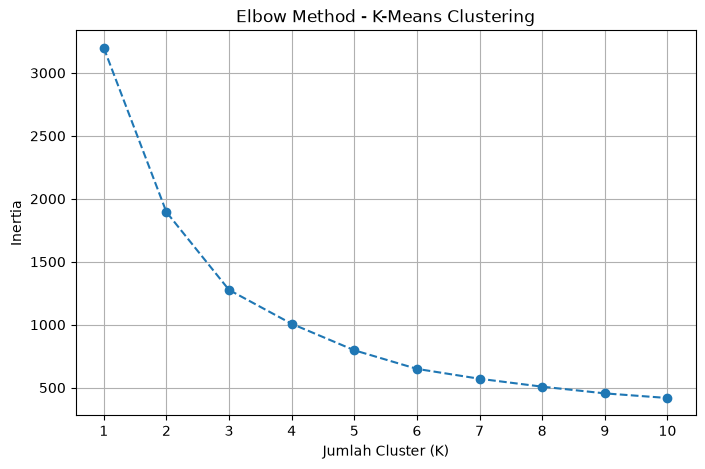

Kandidat Jumlah Cluster Berdasarkan Elbow Method: 3


In [11]:
# Yoseva Faurensia Sitohang_202431195

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 11),
    inertia,
    marker='o',
    linestyle='--' )

plt.title('Elbow Method - K-Means Clustering')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

k_kandidat = 3

print("Kandidat Jumlah Cluster Berdasarkan Elbow Method:", k_kandidat)

In [12]:
# Yoseva Faurensia Sitohang_202431195

hasil_evaluasi = []
for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=0)

    labels = kmeans.fit_predict(fitur_scaled)
    silhouette = silhouette_score(fitur_scaled, labels)
    dbi = davies_bouldin_score(fitur_scaled, labels)

    hasil_evaluasi.append({
        'Jumlah Cluster (K)': k,
        'Silhouette Score': silhouette,
        'Davies-Bouldin Index': dbi})

df_evaluasi = pd.DataFrame(hasil_evaluasi)
display(df_evaluasi.round(4))

,Jumlah Cluster (K),Silhouette Score,Davies-Bouldin Index
0,2,0.3957,1.0064
1,3,0.3591,0.9090
2,4,0.3633,0.9322
3,5,0.3796,0.8782
4,6,0.3839,0.8172


In [13]:
# Yoseva Faurensia Sitohang_202431195

k_terpilih = 3
kmeans_final = KMeans(
    n_clusters=k_terpilih,
    n_init=10,
    random_state=0)

kmeans_final.fit(fitur_scaled)

df_clean['Cluster'] = kmeans_final.labels_

print("Koordinat Centroid:")
print(kmeans_final.cluster_centers_)

print("\nJumlah Anggota Setiap Cluster:")
print(df_clean['Cluster'].value_counts().sort_index())

Koordinat Centroid:
[[-0.39918938  0.99440855]
 [-0.58978116 -0.5424466 ]
 [ 1.27139349 -0.60646101]]

Jumlah Anggota Setiap Cluster:
Cluster
0    583
1    569
2    447
Name: count, dtype: int64


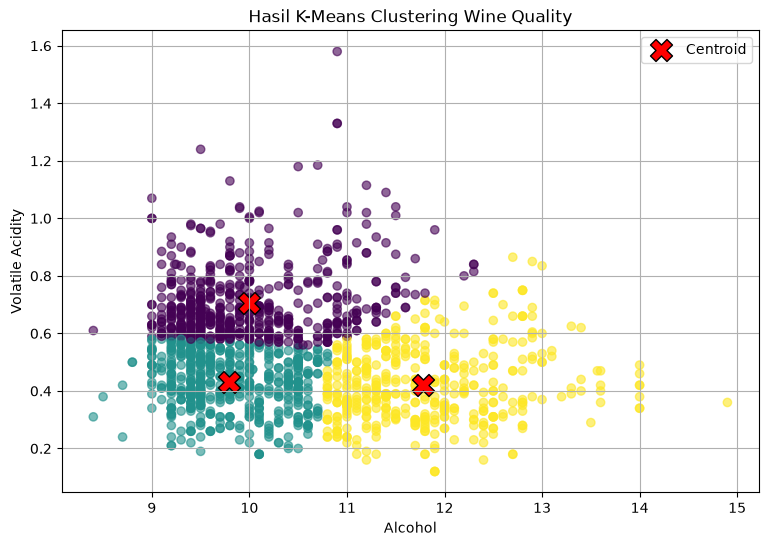

In [14]:
# Yoseva Faurensia Sitohang_202431195

plt.figure(figsize=(9, 6))
plt.scatter(
    fitur['alcohol'],
    fitur['volatile acidity'],
    c=df_clean['Cluster'],
    cmap='viridis',
    alpha=0.6)

centroid_asli = scaler.inverse_transform(
    kmeans_final.cluster_centers_)

plt.scatter(
    centroid_asli[:, 0],
    centroid_asli[:, 1],
    marker='X',
    s=250,
    c='red',
    edgecolors='black',
    label='Centroid')

plt.title('Hasil K-Means Clustering Wine Quality')
plt.xlabel('Alcohol')
plt.ylabel('Volatile Acidity')
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Yoseva Faurensia Sitohang_202431195

profil_cluster = df_clean.groupby('Cluster')[
    ['alcohol', 'volatile acidity']
].mean()

nama_cluster = {
    0: 'Alkohol Sedang - Keasaman Tinggi',
    1: 'Alkohol Rendah - Keasaman Rendah',
    2: 'Alkohol Tinggi - Keasaman Rendah' }

profil_cluster['Nama Cluster'] = profil_cluster.index.map(nama_cluster)
print("Profil dan Nama Setiap Cluster:")
display(profil_cluster.round(3))

Profil dan Nama Setiap Cluster:


,alcohol,volatile acidity,Nama Cluster
Cluster,,,
0,9.998,0.706,Alkohol Sedang - Keasaman Tinggi
1,9.795,0.431,Alkohol Rendah - Keasaman Rendah
2,11.777,0.419,Alkohol Tinggi - Keasaman Rendah


In [16]:
# Yoseva Faurensia Sitohang_202431195

label_akhir = kmeans_final.labels_

silhouette_akhir = silhouette_score(
    fitur_scaled,
    label_akhir)

dbi_akhir = davies_bouldin_score(
    fitur_scaled,
    label_akhir)

print("Evaluasi Akhir Model K-Means")
print("Jumlah Cluster:", k_terpilih)
print("Silhouette Score:", round(silhouette_akhir, 4))
print("Davies-Bouldin Index:", round(dbi_akhir, 4))

Evaluasi Akhir Model K-Means
Jumlah Cluster: 3
Silhouette Score: 0.3591
Davies-Bouldin Index: 0.909
